Modality: CT
Patient Name: CompressedSamples^CT1
Image Size: 128 x 128


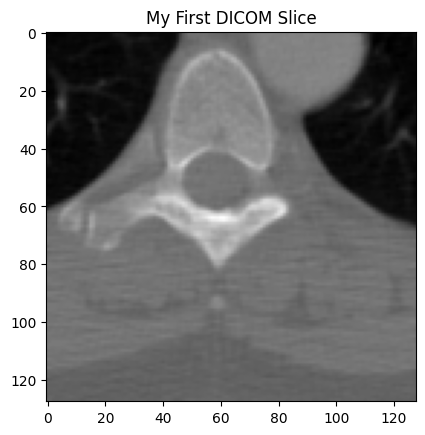

[[1013 1015 1069 1074 1070]
 [1121 1233 1356 1347 1274]
 [1499 1565 1634 1607 1459]
 [1931 1923 1907 1843 1682]
 [2189 2191 2122 2023 1928]]
Rescale Slope: 1
Rescale Intercept: -1024
New Min HU: -896.0
New Max HU: 1167.0


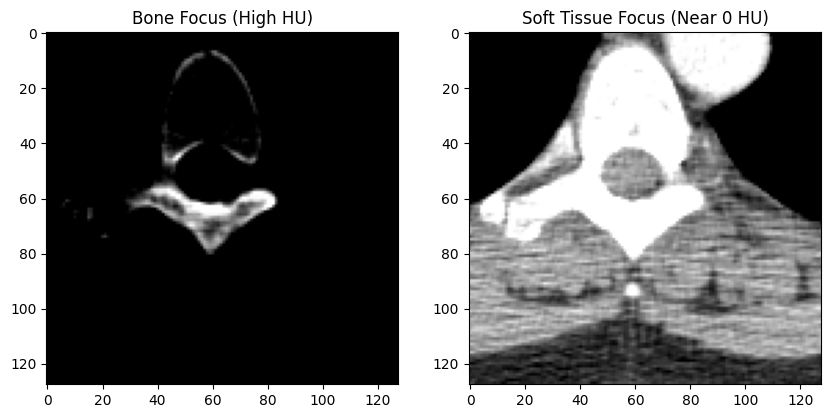

Original range: -896.0 to 1167.0
Normalized range: 0.0 to 1.0


In [ ]:
!pip install pydicom matplotlib numpy
import pydicom
import matplotlib.pyplot as plt
import numpy as np
from pydicom.data import get_testdata_files

# This line finds a sample CT scan that comes hidden inside the library
filename = get_testdata_files("CT_small.dcm")[0]

# Now we 'read' the file
ds = pydicom.dcmread(filename)
print(f"Modality: {ds.Modality}")
print(f"Patient Name: {ds.PatientName}")
print(f"Image Size: {ds.Rows} x {ds.Columns}")
# Convert the DICOM into a grid of numbers
image_array = ds.pixel_array

# Tell matplotlib to show those numbers as a gray picture
plt.imshow(image_array, cmap="gray")
plt.title("My First DICOM Slice")
plt.show()
print(image_array[60:65, 60:65])
# 1. Get the slope and intercept from the metadata (the header)
slope = ds.RescaleSlope
intercept = ds.RescaleIntercept

# 2. Apply the physics formula
hu_image = image_array * slope + intercept

print(f"Rescale Slope: {slope}")
print(f"Rescale Intercept: {intercept}")
print(f"New Min HU: {np.min(hu_image)}")
print(f"New Max HU: {np.max(hu_image)}")
import matplotlib.pyplot as plt

# 1. 'Bone Window': We focus on the high numbers
plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
# We tell the computer: 'Anything below 200 is black, anything above 800 is white'
plt.imshow(hu_image, cmap='gray', vmin=300, vmax=800)
plt.title("Bone Focus (High HU)")

# 2. 'Soft Tissue Window': We focus on the middle numbers
plt.subplot(1, 2, 2)
# We focus on the range around water (0)
plt.imshow(hu_image, cmap='gray', vmin=-150, vmax=150)
plt.title("Soft Tissue Focus (Near 0 HU)")

plt.show()
# Normalizing the entire HU image
hu_min = np.min(hu_image)
hu_max = np.max(hu_image)

norm_image = (hu_image - hu_min) / (hu_max - hu_min)

print(f"Original range: {hu_min} to {hu_max}")
print(f"Normalized range: {np.min(norm_image)} to {np.max(norm_image)}")

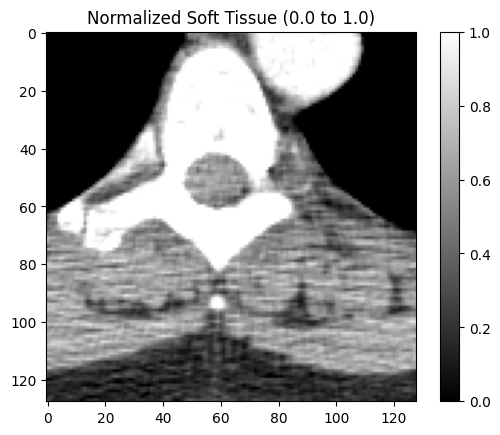

In [ ]:
# 1. Start with your windowed image (Soft Tissue)
# We already used vmin=-150 and vmax=150
windowed = np.clip(hu_image, -150, 150)

# 2. Scale it to 0-1
# Formula: (Image - Min) / (Max - Min)
norm_windowed = (windowed - (-150)) / (150 - (-150))

plt.imshow(norm_windowed, cmap='gray')
plt.title("Normalized Soft Tissue (0.0 to 1.0)")
plt.colorbar()
plt.show()